In [3]:
import re
import numpy as np
import pandas as pd
from datetime import date
EU_CNTRY_CODES = ['AUT', 'BEL', 'BRG', 'HRV', 'CYP', 'CZE', 'DNK', 'EST', 'FIN', 'FRA', 'DEU', 'GRC', 'HUN', 'IRL', 
                  'ITA', 'LVA', 'LTU', 'LUX', 'MLT', 'NLD', 'POL', 'PRT', 'ROU', 'SVK', 'SVN', 'ESP', 'SWE']

<h2>To Do List</h2>
<p>What's left to do?</p>
<ul>
<li>Confirm & merge new data</li>
<li>Source Fiona's new topic mapping (Gdoc?)</li>
<li>Group agenda title and use a filter</li>
</ul>

In [4]:
# Static column mapping
columns = {1: 'ID', '191__a': 'UNDocumentSymbol', '791__a': 'ResolutionSymbol', '245__a': 'TitleStatement', 
           992: 'ActionDate', 996: 'VoteNote', '793__a': 'CommitteeName', '991__c': 'AgendaTitle', 
           '991__d': 'AgendaSubject', '993__a': 'RelatedDocumentSymbols', 967: 'VotingInformation', 
           '650__a': 'TopicSubjects'}

source_path = './source_data/'
source_file = f'{source_path}/NortheasternExport4.xlsx'
df1 = pd.read_excel(source_file, engine='openpyxl').rename(columns=columns)

In [5]:
source_file = f'{source_path}/results_78.xlsx'
df2 = pd.read_excel(source_file, engine='openpyxl').rename(columns=columns)

In [6]:
source_file = f'{source_path}/results_79.xlsx'
df3 = pd.read_excel(source_file, engine='openpyxl').rename(columns=columns)

<h2>New Data Compare</h2>
<i>Data overlap checks</i>
<ul>
<li><b>df1</b> - Original NortheasternExport4.xlsx</li>
<li><b>df2</b> - results_78.xlsx</li>
<li><b>df3</b> - results_79.xlsx</li>
</ul>

<b>81.69%</b> of IDs in new results_78 overlap with original data
Data processing results in a data increase of <b>4.58%</b>, <b>5.28%</b> of existing data was updated.

In [7]:
overlap_ids = df2[df2.ID.isin(df1.ID)].ID.to_list()
print(f'{len(overlap_ids) / df2.shape[0]:.2%} of IDs in new results_78 overlap with original data')

81.69% of IDs in new results_78 overlap with original data


In [8]:
# Is the overlapping data the same?
df1[df1.ID.isin(overlap_ids)].reset_index(drop=True).fillna(0).equals(df2[df2.ID.isin(overlap_ids)].fillna(0))

False

In [9]:
# The new file with overlapping data has at minimum case differences in strings, 'S'ystem is upper cased here.
df1[df1.ID.isin(overlap_ids)].head(1).AgendaTitle.values[0], df2[df2.ID.isin(overlap_ids)].head(1).AgendaTitle.values[0]

('Strengthening of the United Nations system.',
 'Strengthening of the United Nations System.')

In [10]:
# Combine original data, ex-overlap with the new results 78 data
df = pd.concat([df1[~df1.ID.isin(overlap_ids)], df2])

In [11]:
# Check for overlap with the new results 79 data and the current data
df3[df3.ID.isin(df.ID)]

,ID,UNDocumentSymbol,ResolutionSymbol,TitleStatement,ActionDate,VoteNote,CommitteeName,AgendaTitle,AgendaSubject,RelatedDocumentSymbols,VotingInformation,TopicSubjects


In [12]:
# Combine all of the data into the final frame
df = pd.concat([df, df3])

In [13]:
# Overall processing impact
data_increase = (df.shape[0] - df1.shape[0]) / df1.shape[0]
data_update = len(overlap_ids) / df1.shape[0]
print(f'Data processing results in a data increase of {data_increase:.2%}, {data_update:.2%} of existing data was updated.')

Data processing results in a data increase of 4.58%, 5.28% of existing data was updated.


<h2>Process and compute IVC</h2>
<i>Reusing processing code to transform to a matrix of country x resolution</i>

In [14]:
def parse_voting_information(df):
    """
    Parse voting information form dataframe with ID and VotingInformation columns
    Returns: nested dictionary in the form {ID: {CountryCode: Vote}, ...}
    """
    votes_by_id = dict()
    cntry_to_cntry_name = dict()
    for index, row in df.iterrows():
        un_voting_id = row['ID']
        votes = row['VotingInformation']

        # Split the string into a list, changing elements at each numeric character instance
        vote_list = re.split(r'(\D+)', votes)
        # Reduce the list to only the character elements
        vote_list = [x for x in vote_list if not x.isnumeric()]
        
        votes = {}
        for vote in vote_list:
            vote_split = vote.split(';')
            if len(vote_split) > 1:
                country_code = vote_split[1].strip()
                # Avoid empty country code cases
                if len(country_code) > 0:
                    # This first case only applies to Zambia (last country)
                    # the only missing vote info while cntry is there
                    if len(vote_split) > 1 and len(vote_split) < 4:
                        votes[country_code] = np.NaN
                    # Zambia is the last country in the list and has no trailing space char
                    elif len(vote_split) == 4:
                        if vote_split[2].strip() in ['Y', 'N', 'A']:
                            votes[country_code] = vote_split[2].strip()
                            cntry_to_cntry_name[country_code] = vote_split[3].strip()
                    elif len(vote_split) >= 5:
                        votes[country_code] = vote_split[2].strip()
                        cntry_to_cntry_name[country_code] = vote_split[3].strip()
        votes_by_id[un_voting_id] = votes
    return votes_by_id, cntry_to_cntry_name

In [15]:
# Filter source data to only rows that include voting information values
ff = df[(df.VotingInformation.notnull())][['ID', 'VotingInformation']]

# Split the combined country / vote string into parts by ID
res, cntry_to_cntry_name = parse_voting_information(df=ff)

# Confirm the resulting dict object has the same number of rows as the input frame
print(f'Frame row count: {df[df.VotingInformation.notnull()].shape[0]} | processed dict key count: {len(res.keys())}')

Frame row count: 1768 | processed dict key count: 1768


In [16]:
# Matrix of Country x ID of vote values Y, N and NaN (not attended)
xf = pd.DataFrame(res)
xf.head()

,422519,426217,426984,426989,426997,427081,427520,427521,427522,427523,...,3951519,3951523,3952165,3952166,3952167,3952168,3952169,3952170,3952171,3954788
DZA,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,...,Y,A,Y,Y,Y,Y,N,Y,Y,Y
AND,Y,Y,Y,Y,A,Y,N,A,Y,A,...,Y,Y,Y,Y,N,A,Y,Y,A,Y
AGO,Y,Y,Y,Y,Y,NaN,Y,Y,Y,Y,...,Y,Y,Y,Y,Y,Y,A,Y,Y,Y
ATG,Y,Y,Y,Y,Y,A,Y,Y,Y,Y,...,Y,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARG,Y,Y,Y,Y,Y,Y,A,A,Y,A,...,Y,Y,Y,Y,A,Y,Y,Y,Y,Y


<h2>Index of Voting Cohesion</h2>

$$IVC = \frac{2*[(n_{y}-1)*n_{y}+(n_{n}-1)*n_{n}+(n_{a}-1)*n_{a}+n_{a}*(n_{y}+n_{n})-\frac{N^2}{2}+N]}{N^2}

In [17]:
# Compute IVC for EU across all resultions over time
n_y = (xf[xf.index.isin(EU_CNTRY_CODES)] == 'Y').sum()
n_n = (xf[xf.index.isin(EU_CNTRY_CODES)] == 'N').sum()
n_a = (xf[xf.index.isin(EU_CNTRY_CODES)] == 'A').sum()
N = n_y + n_n + n_a
# ivc = 2 * ((n_y-1) * n_y + (n_n-1) * n_n + (n_a-1) * n_a + n_a * (n_y+n_n) - N**2/2+N) / N**2
ivc = (2 * ((n_y-1) * n_y + (n_n-1) * n_n + (n_a-1) * n_a + n_a * (n_y+n_n) - (N**2/2)+N)) / N**2

<AxesSubplot:ylabel='Frequency'>

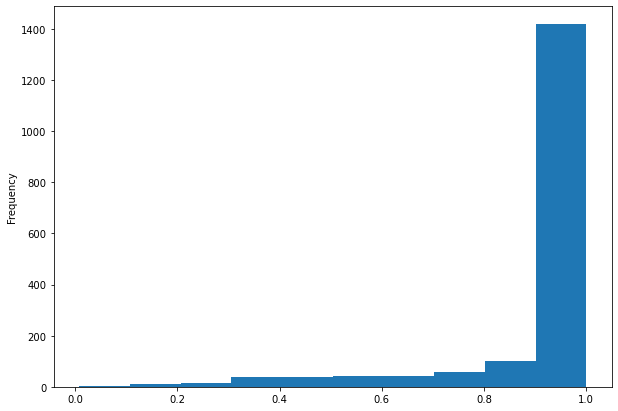

In [18]:
ivc.plot(kind='hist', figsize=(10, 7))

In [19]:
# The paper describes this secnario as "when one-half of the members abstains and the other half votes cohesively 
# with 'yes' or 'no', the index is 0.5 (solidarity vote)." Resolution ID 3952171 appears almost match this case.
print(ivc.tail(5))
xf[xf.index.isin(EU_CNTRY_CODES)].groupby(3952171)[3952171].count()

3952168    0.926036
3952169    1.000000
3952170    1.000000
3952171    0.511834
3954788    1.000000
dtype: float64


3952171
A    15
N    11
Name: 3952171, dtype: int64

In [20]:
ivc

422519     1.000000
426217     0.923200
426984     1.000000
426989     1.000000
426997     1.000000
             ...   
3952168    0.926036
3952169    1.000000
3952170    1.000000
3952171    0.511834
3954788    1.000000
Length: 1768, dtype: float64

<AxesSubplot:>

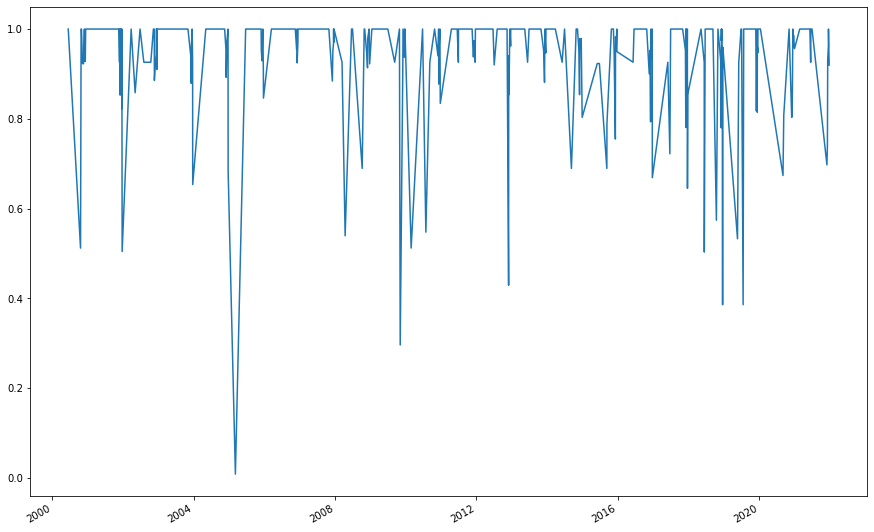

In [22]:
# Map from resolutions to dates and average the IVC across all resolutions for a give date
xivc = ivc.copy()
xivc.index = pd.to_datetime(xivc.index.map(df.set_index('ID')['ActionDate'].to_dict()))
# xivc.groupby(level=0).mean().plot(figsize=(10, 7))

xivc.groupby(level=0).mean().plot(figsize=(15, 10))

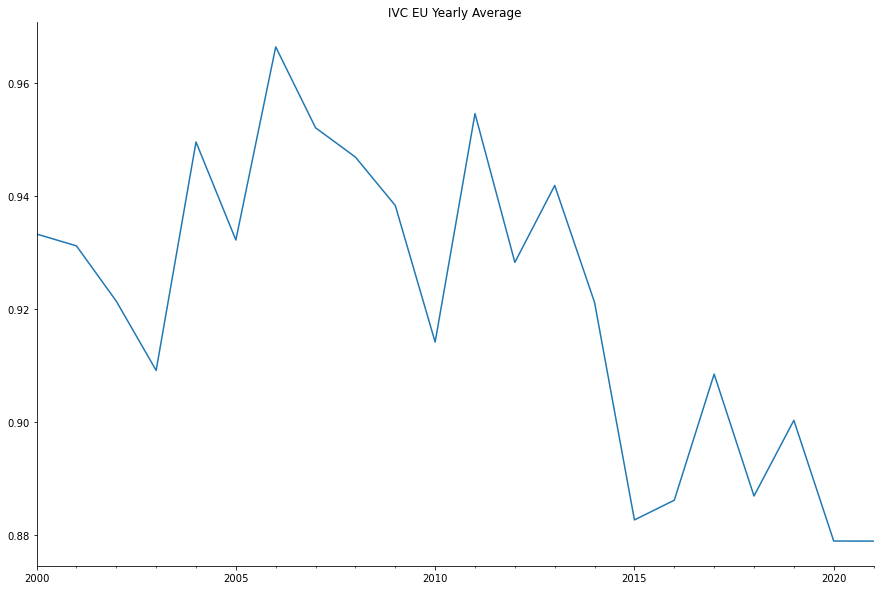

In [23]:
ax = xivc.resample('Y').mean().plot(figsize=(15, 10), title='IVC EU Yearly Average')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

In [31]:
xivc.resample('Y').mean()

2000-12-31    0.933303
2001-12-31    0.931212
2002-12-31    0.921433
2003-12-31    0.909189
2004-12-31    0.949576
2005-12-31    0.932245
2006-12-31    0.966389
2007-12-31    0.952085
2008-12-31    0.946907
2009-12-31    0.938348
2010-12-31    0.914201
2011-12-31    0.954600
2012-12-31    0.928292
2013-12-31    0.941892
2014-12-31    0.921200
2015-12-31    0.882750
2016-12-31    0.886233
2017-12-31    0.908536
2018-12-31    0.886977
2019-12-31    0.900365
2020-12-31    0.879019
2021-12-31    0.879008
dtype: float64

In [363]:
dt = xivc[xivc == xivc.min()].index.values[0]
outlier_vote = df[(df.VotingInformation.notnull()) & (df.ActionDate == dt)]
outlier_vote

,ID,UNDocumentSymbol,ResolutionSymbol,TitleStatement,ActionDate,VoteNote,CommitteeName,AgendaTitle,AgendaSubject,RelatedDocumentSymbols,VotingInformation,TopicSubjects
3813,543081,NaN,A/RES/59/280,United Nations declaration on human cloning :,2005-03-08,84; 34; 37; 36; 191,NaN,International convention against the reproduct...,CLONING OF HUMAN BEINGS--TREATIES (PROPOSED),A/59/516/Add.1,1; AFG; Y; AFGHANISTAN; 2; ALB; Y; ALBANIA; 3;...,NaN


In [321]:
xf[xf.index.isin(EU_CNTRY_CODES)][outlier_vote.ID.to_list()]

,543081
AUT,Y
BEL,N
HRV,Y
CYP,N
CZE,N
DNK,N
EST,N
FIN,N
FRA,N
DEU,Y


In [309]:
xf[xf.index.isin(EU_CNTRY_CODES)].groupby(543081)[543081].count()

543081
A     1
N    13
Y    11
Name: 543081, dtype: int64

In [310]:
n_y = 11
n_n = 13
n_a = 1
N = n_y + n_n + n_a
2 * ((n_y-1) * n_y + (n_n-1) * n_n + (n_a-1) * n_a + n_a * (n_y+n_n) - N**2/2+N) / N**2

0.008

<h2>Confirm resolutions for 2005-03-08</h2>

In [337]:
df[df.ActionDate.dt.date == date(2005, 3, 8)]

,ID,UNDocumentSymbol,ResolutionSymbol,TitleStatement,ActionDate,VoteNote,CommitteeName,AgendaTitle,AgendaSubject,RelatedDocumentSymbols,VotingInformation,TopicSubjects
3813,543081,NaN,A/RES/59/280,United Nations declaration on human cloning :,2005-03-08,84; 34; 37; 36; 191,NaN,International convention against the reproduct...,CLONING OF HUMAN BEINGS--TREATIES (PROPOSED),A/59/516/Add.1,1; AFG; Y; AFGHANISTAN; 2; ALB; Y; ALBANIA; 3;...,NaN
3814,543570,A/RES/59/280,NaN,United Nations Declaration on Human Cloning :,2005-03-08,"Adopted 84-34-37, 82nd plenary meeting",PL,International convention against the reproduct...,CLONING OF HUMAN BEINGS--TREATIES (PROPOSED),A/59/516/Add.1; A/59/PV.82,NaN,HUMAN REPRODUCTIVE TECHNOLOGY; BIOETHICS; LIFE...


In [343]:
xf[543081].loc[xf[543081].notnull().index.isin(EU_CNTRY_CODES)]

AUT      Y
BEL      N
HRV      Y
CYP      N
CZE      N
DNK      N
EST      N
FIN      N
FRA      N
DEU      Y
GRC    NaN
HUN      Y
IRL      Y
ITA      Y
LVA      N
LTU      N
LUX      N
MLT      Y
NLD      N
POL      Y
PRT      Y
ROU      A
SVK      Y
SVN      Y
ESP      N
SWE      N
Name: 543081, dtype: object

In [370]:
df[df.VotingInformation.notnull()].groupby('ActionDate')['ResolutionSymbol'].count().sort_values(ascending=False).head(5)

ActionDate
2005-12-08    40
2019-12-12    35
2020-12-07    35
2018-12-05    34
2016-12-05    31
Name: ResolutionSymbol, dtype: int64

In [388]:
pd.set_option('display.max_colwidth', 400)
df[(pd.to_datetime(df.ActionDate).dt.date == date(2019, 12, 12)) & (df.VotingInformation.notnull())][['ActionDate', 'ResolutionSymbol', 'AgendaTitle']]

,ActionDate,ResolutionSymbol,AgendaTitle
13302,2019-12-12,A/RES/74/66,General and complete disarmament.
13305,2019-12-12,A/RES/74/24,"Objective information on military matters, including transparency of military expenditures."
13306,2019-12-12,A/RES/74/25,Implementation of the Declaration of the Indian Ocean as a Zone of Peace.
13307,2019-12-12,A/RES/74/28,Developments in the field of information and telecommunications in the context of international security.
13308,2019-12-12,A/RES/74/29,Developments in the field of information and telecommunications in the context of international security.
13309,2019-12-12,A/RES/74/30,Establishment of a nuclear-weapon-free zone in the region of the Middle East.
13310,2019-12-12,A/RES/74/31,Conclusion of effective international arrangements to assure non-nuclear-weapon States against the use or threat of use of nuclear weapons.
13311,2019-12-12,A/RES/74/32,Prevention of an arms race in outer space.
13313,2019-12-12,A/RES/74/56,Convening of the 4th special session of the General Assembly devoted to disarmament.
13314,2019-12-12,A/RES/74/59,Follow-up to the advisory opinion of the International Court of Justice on the Legality of the Threat or Use of Nuclear Weapons.
